In [1]:
import numpy,pandas,json,sys
from matplotlib import pyplot
import matplotlib.patches as patches

from geochemistry_helpers import Sampling,GaussianProcess

sys.path.append("../../code/utility")
from load_data import load_cadmium,split_data_by_site,load_carbon

# Set default dpi for saving
pyplot.rcParams['savefig.dpi'] = 600

In [2]:
# Load in data
## Data
data_directory = "../../data/"
d114cd_data = load_cadmium(data_directory)
svalbard_cd_data,arctic_cd_data,northsea_cd_data,kheu_cd_data = split_data_by_site(d114cd_data)

# Collate the ages
ages = d114cd_data["Age model"].values


# Load in GP
d114cd_gp = GaussianProcess().fromJSON(data_directory+"/output/d114cd_gp.json")
d13C_gp = GaussianProcess().fromJSON(data_directory+"/output/d13c_gp.json")

# Load in prior_results
with open(data_directory+"/output/invert_organic_prior_results.json","r") as file:
    prior_results = json.load(file)
# Load in posterior_results
with open(data_directory+"/output/invert_organic_posterior_results.json","r") as file:
    posterior_results = json.load(file)

# Load in metrics
prior_metrics = pandas.read_excel(data_directory+"/output/invert_organic_prior_metrics.xlsx")
posterior_metrics = pandas.read_excel(data_directory+"/output/invert_organic_posterior_metrics.xlsx")

timestep = prior_metrics["time"].values[0]-prior_metrics["time"].values[1]


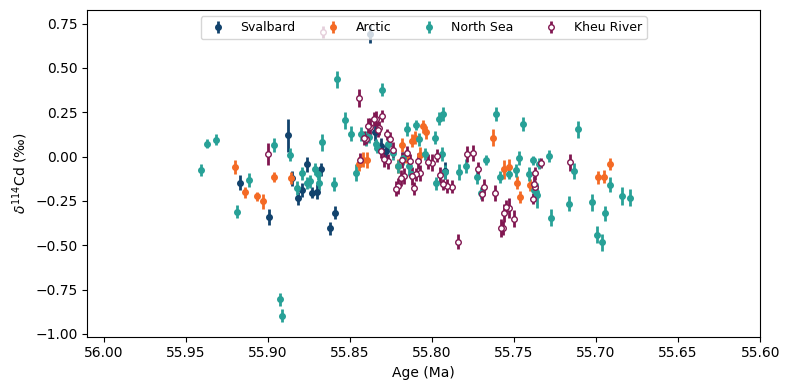

In [3]:
# Plot Data
figure,axis = pyplot.subplots(nrows=1,sharex=True,figsize=(8,4))
axes = [axis]

common_attributes = {"fmt":'o',
                     "zorder":0,
                     "markersize":4,
                     "linewidth":2}
handle_0 = axes[0].errorbar(svalbard_cd_data["Age model"],svalbard_cd_data["δ114Cd(‰)"],yerr=svalbard_cd_data["δ114Cd (2σ)"],color="#12436D",ecolor="#12436D",**common_attributes)
handle_1 = axes[0].errorbar(arctic_cd_data["Age model"],arctic_cd_data["δ114Cd(‰)"],yerr=arctic_cd_data["δ114Cd (2σ)"],color="#F46A25",ecolor="#F46A25",**common_attributes)
handle_2 = axes[0].errorbar(northsea_cd_data["Age model"],northsea_cd_data["δ114Cd(‰)"],yerr=northsea_cd_data["δ114Cd (2σ)"],color="#28A197",ecolor="#28A197",**common_attributes)
handle_3 = axes[0].errorbar(kheu_cd_data["Age model"],kheu_cd_data["δ114Cd(‰)"],yerr=kheu_cd_data["δ114Cd (2σ)"],markeredgecolor="#801650",ecolor="#801650",fmt='o',markerfacecolor="#ffffff",zorder=0,markersize=4,linewidth=2)

axes[0].legend([handle_0,handle_1,handle_2,handle_3],["Svalbard","Arctic","North Sea","Kheu River"],ncols=4,loc="upper center",fontsize=9)

axes[0].set_ylabel("$\\delta^{114}$Cd (‰)")
axes[0].set_xlim((56.01,55.60))

# Add labels
axes[0].set_xlabel("Age (Ma)")

figure.tight_layout()
# figure.savefig("../../figures/cadmium_data.png",transparent=True)


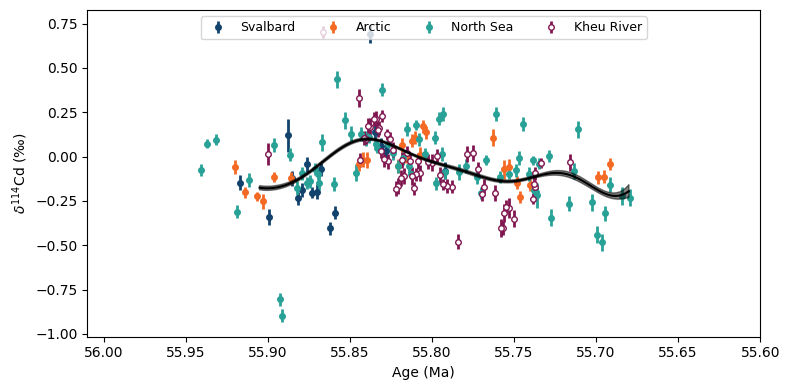

In [4]:
# Plot
figure

d114cd_gp.plotMean(group=-1,color="black",axis=axes[0])
d114cd_gp.plotArea(group=-1,color="black",alpha=0.5,set_axes=False,axis=axes[0])

axes[0].set_ylabel("$\\delta^{114}$Cd (‰)")

# axes[0].invert_xaxis()

figure.tight_layout()
figure.savefig("../../figures/cadmium_data_gp.png",transparent=True)


figure

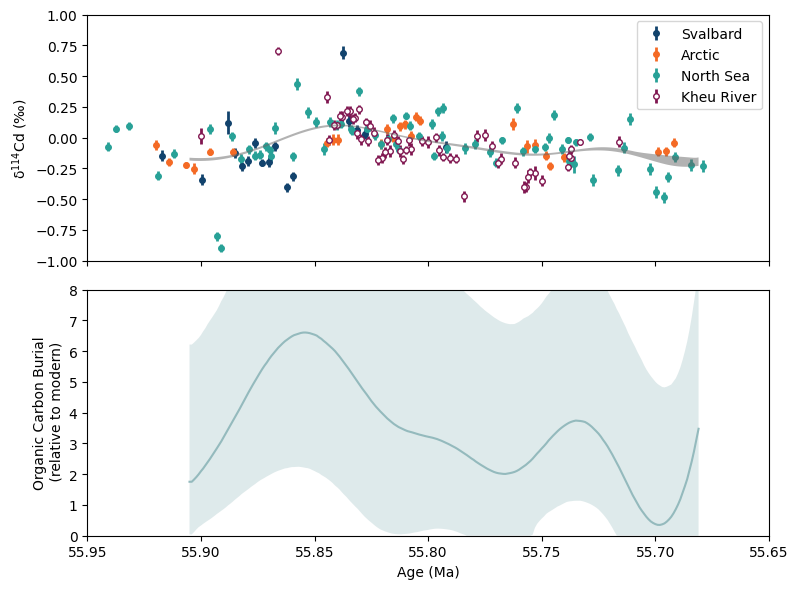

In [5]:
# Plot
figure,axes = pyplot.subplots(nrows=2,sharex=True,figsize=(8,6))

common_attributes = {"fmt":'o',
                     "zorder":0,
                     "markersize":4,
                     "linewidth":2}
handle_0 = axes[0].errorbar(svalbard_cd_data["Age model"],svalbard_cd_data["δ114Cd(‰)"],yerr=svalbard_cd_data["δ114Cd (2σ)"],color="#12436D",ecolor="#12436D",**common_attributes)
handle_1 = axes[0].errorbar(arctic_cd_data["Age model"],arctic_cd_data["δ114Cd(‰)"],yerr=arctic_cd_data["δ114Cd (2σ)"],color="#F46A25",ecolor="#F46A25",**common_attributes)
handle_2 = axes[0].errorbar(northsea_cd_data["Age model"],northsea_cd_data["δ114Cd(‰)"],yerr=northsea_cd_data["δ114Cd (2σ)"],color="#28A197",ecolor="#28A197",**common_attributes)
handle_3 = axes[0].errorbar(kheu_cd_data["Age model"],kheu_cd_data["δ114Cd(‰)"],yerr=kheu_cd_data["δ114Cd (2σ)"],markeredgecolor="#801650",ecolor="#801650",fmt='o',markerfacecolor="#ffffff",zorder=0,markersize=4,linewidth=2)

axes[0].legend([handle_0,handle_1,handle_2,handle_3],["Svalbard","Arctic","North Sea","Kheu River"])

indices = range(0,len(prior_results))
colormap = pyplot.colormaps.get_cmap("autumn")(numpy.linspace(0,1,len(indices)))

time = prior_metrics["time"].values
interpolation_ages = [ages,time]

# First subplot
d114Cd_prior_patch_x = numpy.concatenate((numpy.array(time),numpy.array(time[::-1]))) 
d114Cd_prior_patch_y = numpy.concatenate((numpy.array(prior_metrics["seawater_d114Cd_lower_quantile"]),
                                    numpy.array(prior_metrics["seawater_d114Cd_upper_quantile"][::-1])))

d114Cd_prior_patch = patches.Polygon(numpy.concatenate((d114Cd_prior_patch_x[:,numpy.newaxis],d114Cd_prior_patch_y[:,numpy.newaxis]),axis=1),facecolor="#666666",alpha=0.5)
axes[0].add_patch(d114Cd_prior_patch)



axes[0].set_ylim((-1.0,1.0))
axes[0].set_ylabel("δ$^{114}$Cd (‰)")


# Second subplot
organic_prior_patch_x = numpy.concatenate((numpy.array(time),numpy.array(time[::-1]))) 
organic_prior_patch_y = numpy.concatenate((numpy.array(prior_metrics["organic_flux_lower_quantile"]/5287500),
                                    numpy.array(prior_metrics["organic_flux_upper_quantile"][::-1]/5287500)))

organic_prior_patch = patches.Polygon(numpy.concatenate((organic_prior_patch_x[:,numpy.newaxis],
                                                                    organic_prior_patch_y[:,numpy.newaxis]),
                                                                    axis=1),
                                                         facecolor="#94babd",
                                                         alpha=0.3)
axes[1].add_patch(organic_prior_patch)
axes[1].plot(time,prior_metrics["organic_flux_median"]/5287500,color="#94babd",linestyle="-")

axes[1].set_xlim((55.95,55.65))
axes[1].set_ylim((0.0,8.0))

axes[1].set_xlabel("Age (Ma)")
axes[1].set_ylabel("Organic Carbon Burial\n (relative to modern)")

figure.tight_layout()
figure.savefig("../../figures/cadmium_prior.png",transparent=True)

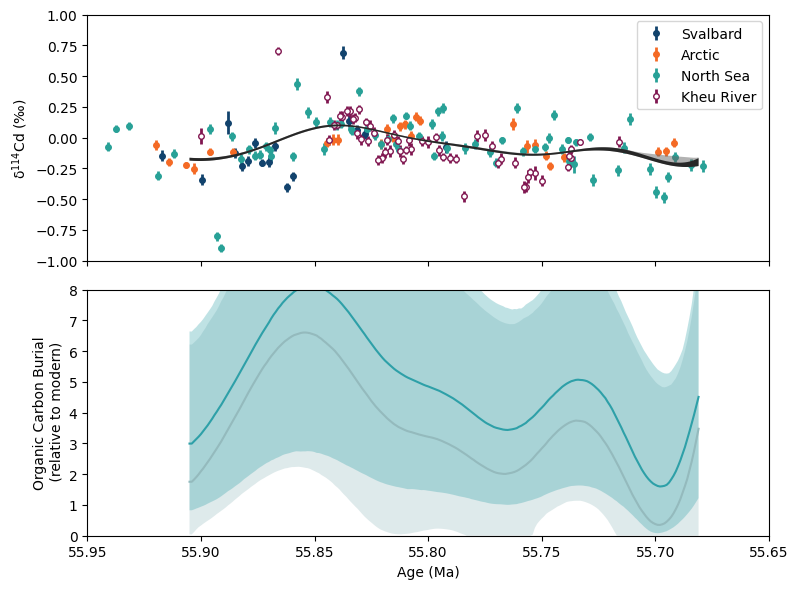

In [6]:
d114Cd_posterior_patch_x = numpy.concatenate((numpy.array(time),numpy.array(time[::-1])))
d114Cd_posterior_patch_y = numpy.concatenate((numpy.array(posterior_metrics["seawater_d114Cd_lower_quantile"]),
                                    numpy.array(posterior_metrics["seawater_d114Cd_upper_quantile"][::-1])))
d114Cd_posterior_patch = patches.Polygon(numpy.concatenate((d114Cd_posterior_patch_x[:,numpy.newaxis],d114Cd_posterior_patch_y[:,numpy.newaxis]),axis=1),facecolor="#272727",alpha=1.0)
axes[0].add_patch(d114Cd_posterior_patch)


organic_posterior_patch_x = numpy.concatenate((numpy.array(time),numpy.array(time[::-1])))
organic_posterior_patch_y = numpy.concatenate((numpy.array(posterior_metrics["organic_flux_lower_quantile"]/5287500),
                                    numpy.array(posterior_metrics["organic_flux_upper_quantile"][::-1]/5287500)))

organic_posterior_patch = patches.Polygon(numpy.concatenate((organic_posterior_patch_x[:,numpy.newaxis],
                                                                        organic_posterior_patch_y[:,numpy.newaxis]),
                                                                        axis=1),
                                                                facecolor="#2ea0a8",
                                                                alpha=0.3)
axes[1].add_patch(organic_posterior_patch)
axes[1].plot(time,posterior_metrics["organic_flux_median"]/5287500,color="#2ea0a8",linestyle="-")

figure.savefig("../../figures/cadmium_posterior.png",transparent=True)
figure




Text(0, 0.5, 'Organic Carbon Burial\n (relative to modern)')

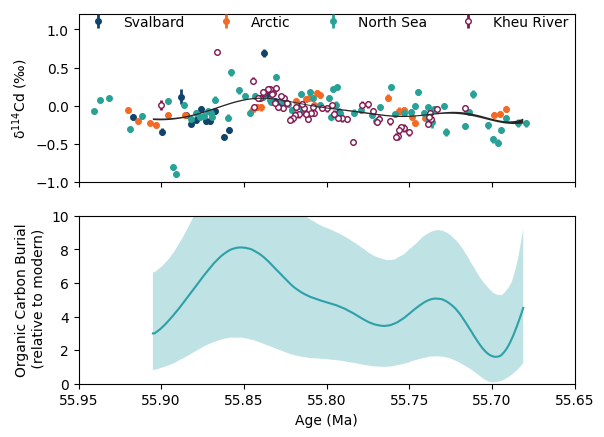

In [7]:
# Plot
figure,axes = pyplot.subplots(nrows=2,sharex=True)

common_attributes = {"fmt":'o',
                     "zorder":0,
                     "markersize":4,
                     "linewidth":2}
handle_0 = axes[0].errorbar(svalbard_cd_data["Age model"],svalbard_cd_data["δ114Cd(‰)"],yerr=svalbard_cd_data["δ114Cd (2σ)"],color="#12436D",ecolor="#12436D",**common_attributes)
handle_1 = axes[0].errorbar(arctic_cd_data["Age model"],arctic_cd_data["δ114Cd(‰)"],yerr=arctic_cd_data["δ114Cd (2σ)"],color="#F46A25",ecolor="#F46A25",**common_attributes)
handle_2 = axes[0].errorbar(northsea_cd_data["Age model"],northsea_cd_data["δ114Cd(‰)"],yerr=northsea_cd_data["δ114Cd (2σ)"],color="#28A197",ecolor="#28A197",**common_attributes)
handle_3 = axes[0].errorbar(kheu_cd_data["Age model"],kheu_cd_data["δ114Cd(‰)"],yerr=kheu_cd_data["δ114Cd (2σ)"],markeredgecolor="#801650",ecolor="#801650",fmt='o',markerfacecolor="#ffffff",zorder=0,markersize=4,linewidth=2)

axes[0].legend([handle_0,handle_1,handle_2,handle_3],["Svalbard","Arctic","North Sea","Kheu River"],ncols=4,loc="upper center",bbox_to_anchor=(0,0.07,1,1),frameon=False)

indices = range(0,len(prior_results))
colormap = pyplot.colormaps.get_cmap("autumn")(numpy.linspace(0,1,len(indices)))


time = prior_metrics["time"].values
interpolation_ages = [ages,time]

# First subplot
d114Cd_posterior_patch_x = numpy.concatenate((numpy.array(time),numpy.array(time[::-1])))
d114Cd_posterior_patch_y = numpy.concatenate((numpy.array(posterior_metrics["seawater_d114Cd_lower_quantile"][0:]),
                                    numpy.array(posterior_metrics["seawater_d114Cd_upper_quantile"][0:][::-1])))
d114Cd_posterior_patch = patches.Polygon(numpy.concatenate((d114Cd_posterior_patch_x[:,numpy.newaxis],d114Cd_posterior_patch_y[:,numpy.newaxis]),axis=1),facecolor="#272727",alpha=1.0)
axes[0].add_patch(d114Cd_posterior_patch)

axes[0].set_ylim((-1.0,1.2))
axes[0].set_ylabel("δ$^{114}$Cd (‰)")


# Second subplot
organic_posterior_patch_x = numpy.concatenate((numpy.array(time),numpy.array(time[::-1])))
organic_posterior_patch_y = numpy.concatenate((numpy.array(posterior_metrics["organic_flux_lower_quantile"][0:]/5287500),
                                    numpy.array(posterior_metrics["organic_flux_upper_quantile"][0:][::-1]/5287500)))

organic_posterior_patch = patches.Polygon(numpy.concatenate((organic_posterior_patch_x[:,numpy.newaxis],
                                                                        organic_posterior_patch_y[:,numpy.newaxis]),
                                                                        axis=1),
                                                                facecolor="#2ea0a8",
                                                                alpha=0.3)
axes[1].add_patch(organic_posterior_patch)
axes[1].plot(time,posterior_metrics["organic_flux_median"][0:]/5287500,color="#2ea0a8",linestyle="-")


axes[1].set_xlim((55.95,55.65))
axes[1].set_ylim((0.0,10.0))

axes[1].set_xlabel("Age (Ma)")
axes[1].set_ylabel("Organic Carbon Burial\n (relative to modern)")

# figure.tight_layout()
# figure.savefig("./figures/cadmium_prior.png",transparent=True)


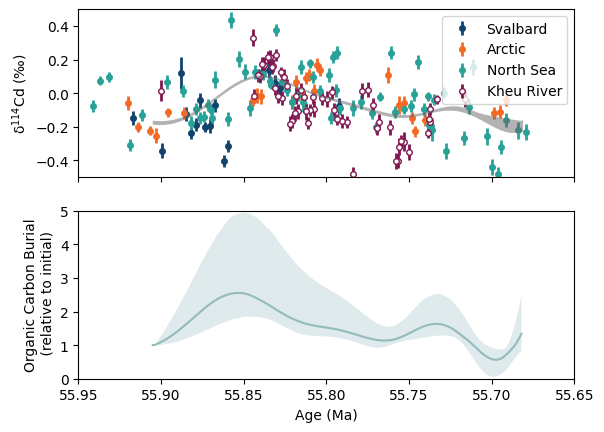

In [8]:
# Plot
figure,axes = pyplot.subplots(nrows=2,sharex=True)
common_attributes = {"fmt":'o',
                     "zorder":0,
                     "markersize":4,
                     "linewidth":2}
handle_0 = axes[0].errorbar(svalbard_cd_data["Age model"],svalbard_cd_data["δ114Cd(‰)"],yerr=svalbard_cd_data["δ114Cd (2σ)"],color="#12436D",ecolor="#12436D",**common_attributes)
handle_1 = axes[0].errorbar(arctic_cd_data["Age model"],arctic_cd_data["δ114Cd(‰)"],yerr=arctic_cd_data["δ114Cd (2σ)"],color="#F46A25",ecolor="#F46A25",**common_attributes)
handle_2 = axes[0].errorbar(northsea_cd_data["Age model"],northsea_cd_data["δ114Cd(‰)"],yerr=northsea_cd_data["δ114Cd (2σ)"],color="#28A197",ecolor="#28A197",**common_attributes)
handle_3 = axes[0].errorbar(kheu_cd_data["Age model"],kheu_cd_data["δ114Cd(‰)"],yerr=kheu_cd_data["δ114Cd (2σ)"],markeredgecolor="#801650",ecolor="#801650",fmt='o',markerfacecolor="#ffffff",zorder=0,markersize=4,linewidth=2)

axes[0].legend([handle_0,handle_1,handle_2,handle_3],["Svalbard","Arctic","North Sea","Kheu River"])


# cadmium_gp.plotArea(axis=axes[0],group=-1,color="#aaaaaa",alpha=0.5,set_axes=False,zorder=1)
# cadmium_gp.plotMean(axis=axes[0],group=-1,color="#666666",linestyle="--",zorder=2)

indices = range(0,len(prior_results))
colormap = pyplot.colormaps.get_cmap("autumn")(numpy.linspace(0,1,len(indices)))

time = prior_metrics["time"].values
interpolation_ages = [ages,time]

# First subplot
d114Cd_prior_patch_x = numpy.concatenate((numpy.array(time),numpy.array(time[::-1]))) 
d114Cd_prior_patch_y = numpy.concatenate((numpy.array(prior_metrics["seawater_d114Cd_lower_quantile"]),
                                    numpy.array(prior_metrics["seawater_d114Cd_upper_quantile"][::-1])))

d114Cd_prior_patch = patches.Polygon(numpy.concatenate((d114Cd_prior_patch_x[:,numpy.newaxis],d114Cd_prior_patch_y[:,numpy.newaxis]),axis=1),facecolor="#666666",alpha=0.5)
axes[0].add_patch(d114Cd_prior_patch)



axes[0].set_ylim((-0.5,0.5))
axes[0].set_ylabel("δ$^{114}$Cd (‰)")


# Second subplot
organic_prior_patch_x = numpy.concatenate((numpy.array(time[0:-1]),numpy.array(time[0:-1][::-1]))) 
organic_prior_patch_y = numpy.concatenate((numpy.array(posterior_metrics["relative_organic_flux_lower_quantile"][0:-1]),
                                    numpy.array(posterior_metrics["relative_organic_flux_upper_quantile"][0:-1][::-1])))

organic_prior_patch = patches.Polygon(numpy.concatenate((organic_prior_patch_x[:,numpy.newaxis],
                                                                    organic_prior_patch_y[:,numpy.newaxis]),
                                                                    axis=1),
                                                         facecolor="#94babd",
                                                         alpha=0.3)
axes[1].add_patch(organic_prior_patch)
axes[1].plot(time[0:-1],posterior_metrics["relative_organic_flux_median"][0:-1],color="#94babd",linestyle="-")

axes[1].set_xlim((55.95,55.65))
axes[1].set_ylim((0.0,5.0))

axes[1].set_xlabel("Age (Ma)")
axes[1].set_ylabel("Organic Carbon Burial\n (relative to initial)")

pyplot.show()

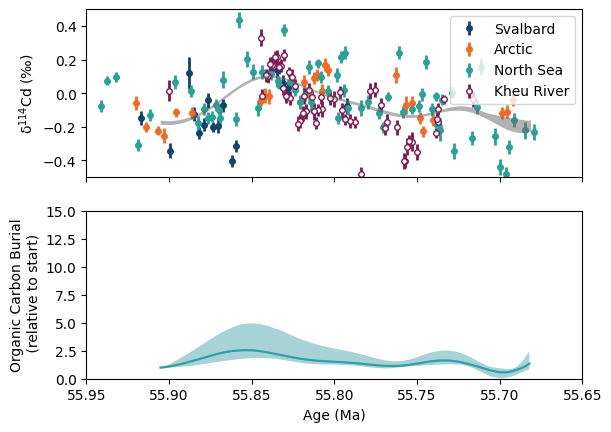

In [9]:
# Second subplot
organic_posterior_patch_x = numpy.concatenate((numpy.array(time[0:-1]),numpy.array(time[0:-1][::-1]))) 
organic_posterior_patch_y = numpy.concatenate((numpy.array(posterior_metrics["relative_organic_flux_lower_quantile"][0:-1]),
                                    numpy.array(posterior_metrics["relative_organic_flux_upper_quantile"][0:-1][::-1])))

organic_posterior_patch = patches.Polygon(numpy.concatenate((organic_posterior_patch_x[:,numpy.newaxis],
                                                                    organic_posterior_patch_y[:,numpy.newaxis]),
                                                                    axis=1),
                                                         facecolor="#2ea0a8",
                                                         alpha=0.3)
axes[1].add_patch(organic_posterior_patch)
axes[1].plot(time[0:-1],posterior_metrics["relative_organic_flux_median"][0:-1],color="#2ea0a8",linestyle="-")

axes[1].set_ylim((0.0,15.0))
axes[1].set_ylabel("Organic Carbon Burial\n (relative to start)")
axes[1].set_xlabel("Age (Ma)")


figure


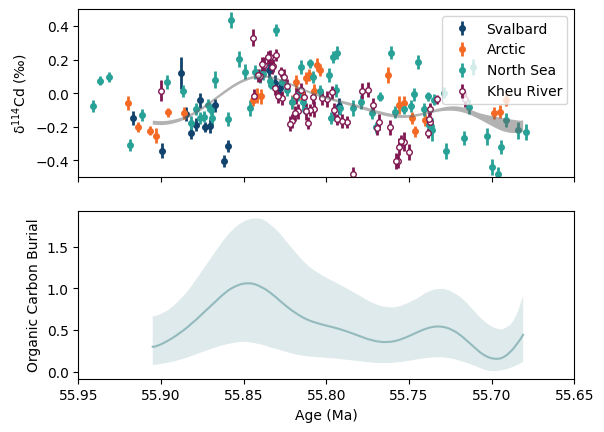

In [10]:
# Plot
figure,axes = pyplot.subplots(nrows=2,sharex=True)
common_attributes = {"fmt":'o',
                     "zorder":0,
                     "markersize":4,
                     "linewidth":2}
handle_0 = axes[0].errorbar(svalbard_cd_data["Age model"],svalbard_cd_data["δ114Cd(‰)"],yerr=svalbard_cd_data["δ114Cd (2σ)"],color="#12436D",ecolor="#12436D",**common_attributes)
handle_1 = axes[0].errorbar(arctic_cd_data["Age model"],arctic_cd_data["δ114Cd(‰)"],yerr=arctic_cd_data["δ114Cd (2σ)"],color="#F46A25",ecolor="#F46A25",**common_attributes)
handle_2 = axes[0].errorbar(northsea_cd_data["Age model"],northsea_cd_data["δ114Cd(‰)"],yerr=northsea_cd_data["δ114Cd (2σ)"],color="#28A197",ecolor="#28A197",**common_attributes)
handle_3 = axes[0].errorbar(kheu_cd_data["Age model"],kheu_cd_data["δ114Cd(‰)"],yerr=kheu_cd_data["δ114Cd (2σ)"],markeredgecolor="#801650",ecolor="#801650",fmt='o',markerfacecolor="#ffffff",zorder=0,markersize=4,linewidth=2)

axes[0].legend([handle_0,handle_1,handle_2,handle_3],["Svalbard","Arctic","North Sea","Kheu River"])


# cadmium_gp.plotArea(axis=axes[0],group=-1,color="#aaaaaa",alpha=0.5,set_axes=False,zorder=1)
# cadmium_gp.plotMean(axis=axes[0],group=-1,color="#666666",linestyle="--",zorder=2)

indices = range(0,len(prior_results))
colormap = pyplot.colormaps.get_cmap("autumn")(numpy.linspace(0,1,len(indices)))

time = prior_metrics["time"].values
interpolation_ages = [ages,time]

# First subplot
d114Cd_prior_patch_x = numpy.concatenate((numpy.array(time),numpy.array(time[::-1]))) 
d114Cd_prior_patch_y = numpy.concatenate((numpy.array(prior_metrics["seawater_d114Cd_lower_quantile"]),
                                    numpy.array(prior_metrics["seawater_d114Cd_upper_quantile"][::-1])))

d114Cd_prior_patch = patches.Polygon(numpy.concatenate((d114Cd_prior_patch_x[:,numpy.newaxis],d114Cd_prior_patch_y[:,numpy.newaxis]),axis=1),facecolor="#666666",alpha=0.5)
axes[0].add_patch(d114Cd_prior_patch)



axes[0].set_ylim((-0.5,0.5))
axes[0].set_ylabel("δ$^{114}$Cd (‰)")


# Second subplot
organic_prior_patch_x = numpy.concatenate((numpy.array(time),numpy.array(time[::-1]))) 
organic_prior_patch_y = numpy.concatenate((numpy.array(posterior_metrics["organic_flux_per_yr_lower_quantile"]),
                                    numpy.array(posterior_metrics["organic_flux_per_yr_upper_quantile"][::-1])))

organic_prior_patch = patches.Polygon(numpy.concatenate((organic_prior_patch_x[:,numpy.newaxis],
                                                                    organic_prior_patch_y[:,numpy.newaxis]),
                                                                    axis=1),
                                                         facecolor="#94babd",
                                                         alpha=0.3)
axes[1].add_patch(organic_prior_patch)
axes[1].plot(time,posterior_metrics["organic_flux_per_yr_median"],color="#94babd",linestyle="-")

axes[1].set_xlim((55.95,55.65))
# axes[1].set_ylim((0.0,5.0))

axes[1].set_xlabel("Age (Ma)")
axes[1].set_ylabel("Organic Carbon Burial")

pyplot.show()
